# ***CT5120: Introduction to NLP***

# ***Assignment 2: Counter-Narrative Generation*** (Total 100 marks)
This assignment focuses on **Counter-Narrative Generation** for hate speech.

A Counter-Narrative (CN) is a non-aggressive response that offers feedback
through fact-bound arguments and is considered as
the most effective approach to withstand hate messages

---

###  **Student Details**

Enter your

**Name:** William Vida

**Student ID:** 22749181

---

>  <font color="red">**Disclaimer:** This assignment may contain hate speech and offensive content, strictly for academic purposes. </font>

---
**Deadline:** **`01:45 PM, 23rd October, 2026`** (Ireland Time)

**Submission Format:** `.ipynb`

**Individual Assignment:** This is an individual assignment - your work must be your own.

<!-- ---

### 🚫 Academic Integrity

<font color="red">**Strictly no Generative AI.**</font> Do the assignment by yourself - write code and answers fully in your own words, without using AI tools.

<font color="red">**Note:**</font> You must **disable the AI features on Google Colab** before working on this assignment.
📺 Guide: [How to disable AI in Colab](https://youtu.be/qrGZv8nPh1o) -->



---

### **In-Lab Grading — "Defend Your Work!**"

Think of this as a **mini viva** — you built it, so you should be able to talk through it.

| | |
|---|---|
|  **When** | `October 09th`, `October 16th` & `October 23rd, 2026` [12:00 PM to 02:00 PM] |
|  **What** | A short, friendly Q&A with your TAs |
|  **How** | TAs will ask you a few questions about your notebook |

>  **Pro tip:** You don't need to memorise every line. If you understand *What, How, & Why* you made each decision, you'll breeze through this.

No surprises, no trick questions - just show us it's genuinely **your work, and your understanding.**



---

## **Task Roadmap**

| # | Section | Focus | Marks |
|---|---|---|---:|
| 1 | **Dataset & Task Understanding** | Explore the hate-speech / counter-narrative dataset | **30** |
| 2️ | **Counter-Narrative Generation Method** | Build instruction-based LLM generation and evaluate responses | **40** |
| 3️ | **Improving Generation & Comparison** | Implement an improvement (e.g., RAG) and compare performance | **30** |
|  |  | **Total** | **100** |

Each section builds on the previous one:

**Dataset → Generation Method → Improving Generation & Comparison**

## Dataset

This assignment must use a **Counter-Narrative Generation dataset**.

You may choose **one of the example datasets listed below**, or use another appropriate publicly available counter-narrative dataset.

### Example Datasets

*   Multitarget-CONAN - https://drive.google.com/file/d/1dueNK0SnRidLmuLhUfErmDWb0cWZcQ0W/view?usp=sharing
*   CONAN - https://drive.google.com/file/d/1aSWImoHwNgRnKME18cJn8BMg9C5pjlgH/view?usp=sharing
*   Counter-Narrative-ENG - https://drive.google.com/file/d/1IQuhXKsR-ueB2MCS-I3K3GGKN3wbMKpO/view?usp=sharing
*   Multitarget-CONAN - https://drive.google.com/file/d/1MY4jIHdDa0YhXHNWctP0YrzfemyLuigL/view?usp=sharing

If you choose a different dataset, it should contain, or be easily mapped to, the following information:

- `HATE_SPEECH` — a hateful statement;
- `COUNTER_NARRATIVE` — a human-written counter-narrative;
- `TARGET` — the target group of the hate speech.

> You will use the **training data** for building the generation method and retrieval examples, and the **test data** only for final evaluation.

Tutorial: [Loading a CSV using Hugging Face Datasets library](https://huggingface.co/docs/datasets/tabular_load#csv-files)

# Installing and Importing Packages

> **Note:** You may use any packages required for your experiments.

# Installing and Importing Packages

> **Note:** This is a setup cell and is not directly graded. You may install and import any Python packages required for your experiments.  
> Commonly useful libraries may include `pandas`, `numpy`, `matplotlib`, `transformers`, `torch`, `sentence-transformers`, and `evaluate`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from bert_score import BERTScorer
from rouge_score import rouge_scorer
from sacrebleu import corpus_bleu
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import StratifiedGroupKFold
from transformers import AutoModelForCausalLM, AutoTokenizer

/Users/william/Documents/University of Galway/Introduction to Natural Language Processing/Assignment 2 Counter-Narrative Generation/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1023 14:03:35.166000 54137 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


---

# **Section 1: Dataset & Counter-Narrative Task Understanding**

### `Total = 30 marks`
Before you touch any code, pick your dataset and get to know it. This section is about **choosing well and showing you understand what you chose.** You can either use the below given datasets, or find relevant dataset.

Before generating counter-narratives, you first need to understand the dataset and the relationship between the **hate-speech input** and the **counter-narrative response**.

In this section, you will inspect the dataset, explore its main characteristics, visualise important patterns, and explain what you observe.

| Task | What you'll do | Marks |
|---|---|---:|
| **1a** | Inspect the dataset | `10` |
| **1c** | Perform text analysis and visualisation | `10` |
| **1d** | Explain your observations | `10` |

>  The goal of this section is to understand the data before building the generation system in the next section.

#**1a: Dataset (Explore hate-speech targets and response characteristics)** (10 marks)
Load your chosen dataset, count the occurrences of each target category, and compute summary statistics (lengths) of both hate speech and counter-narratives.

In [2]:
# Basic information about the dataset.
df = pd.read_csv("Multitarget-CONAN.csv")
print("Columns", df.columns)
print("Shape", df.shape)

# Check for missing data.
missing = df.isnull().sum()
print("\nMissing data")
print(missing)

# Get information about the classes.
distribution = df["TARGET"].value_counts().sort_index().to_frame("count")
distribution["percentage"] = distribution["count"] / distribution["count"].sum() * 100
print("\nClass distribution\n", distribution)
print("Number of unique labels", len(pd.unique(df.TARGET)))

# Remove the INDEX and VERSION columns.
df = df.drop(columns=["INDEX", "VERSION"])
df = df.reset_index(drop=True)
print("\nRemove the INDEX and VERSION columns.")
print("Columns", df.columns)

Columns Index(['INDEX', 'HATE_SPEECH', 'COUNTER_NARRATIVE', 'TARGET', 'VERSION'], dtype='str')
Shape (5003, 5)

Missing data
INDEX                0
HATE_SPEECH          0
COUNTER_NARRATIVE    0
TARGET               0
VERSION              0
dtype: int64

Class distribution
           count  percentage
TARGET                     
DISABLED    220    4.397362
JEWS        594   11.872876
LGBT+       617   12.332600
MIGRANTS    957   19.128523
MUSLIMS    1335   26.683990
POC         352    7.035779
WOMEN       662   13.232061
other       266    5.316810
Number of unique labels 8

Remove the INDEX and VERSION columns.
Columns Index(['HATE_SPEECH', 'COUNTER_NARRATIVE', 'TARGET'], dtype='str')


# **1b: Text analysis and Visualization** (10 marks)
Create two clear, labeled plots: a bar chart showing hate target distributions, and a distribution comparison of input vs. response text lengths.


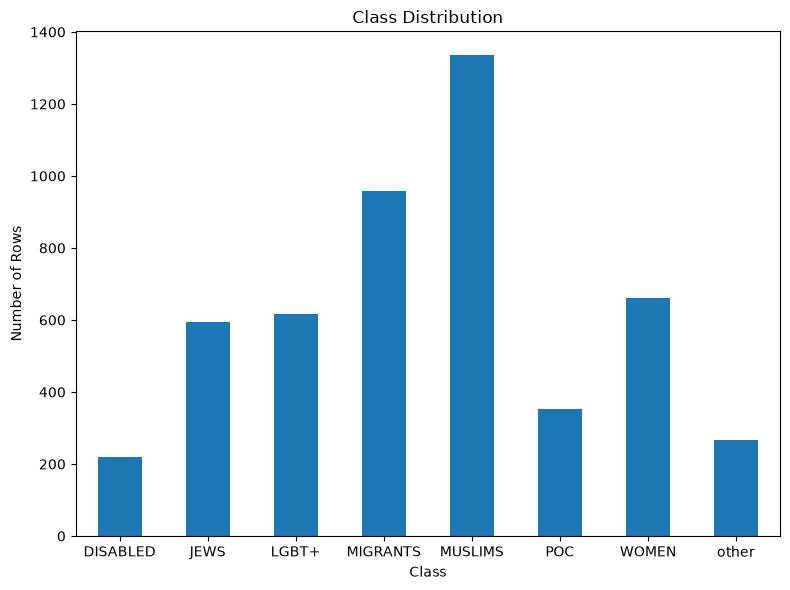

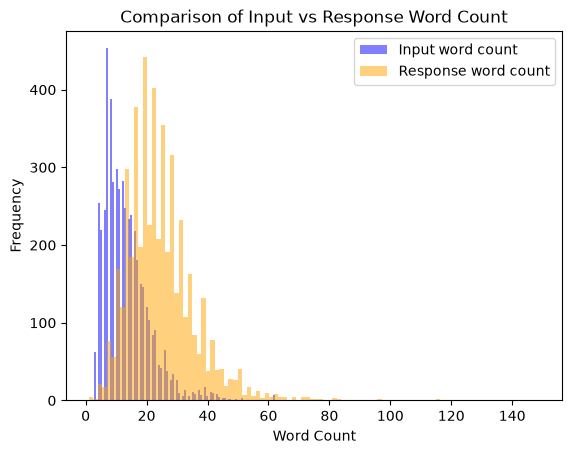

,HATE_SPEECH_WORDS,COUNTER_NARRATIVE_WORDS
count,5003.000000,5003.000000
mean,13.223666,24.769938
std,7.792141,11.407628
min,2.000000,1.000000
25%,8.000000,17.000000
50%,12.000000,23.000000
75%,17.000000,30.000000
max,68.000000,149.000000


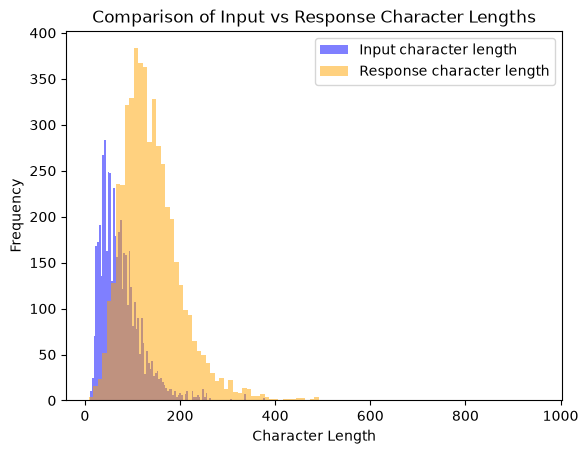

,HATE_SPEECH_LENGTH,COUNTER_NARRATIVE_LENGTH
count,5003.000000,5003.000000
mean,75.456726,140.686388
std,44.426546,66.874110
min,11.000000,8.000000
25%,43.000000,97.000000
50%,66.000000,130.000000
75%,95.000000,171.000000
max,379.000000,956.000000


In [3]:
# Create a bar chart about the class distribution.
df["TARGET"].value_counts().sort_index().plot(kind="bar", figsize=(8, 6))
plt.xlabel("Class")
plt.ylabel("Number of Rows")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Get the HATE_SPEECH and COUNTER_NARRATIVE character lengths.
input_word_length = [len(x.split()) for x in df["HATE_SPEECH"].tolist()]
response_word_length = [len(x.split()) for x in df["COUNTER_NARRATIVE"].tolist()]

# Create a histogram of the HATE_SPEECH and COUNTER_NARRATIVE word count.
plt.hist(
    input_word_length,
    color="blue",
    alpha=0.5,
    bins=100,
    label="Input word count",
)
plt.hist(
    response_word_length,
    color="orange",
    alpha=0.5,
    bins=100,
    label="Response word count",
)
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.legend()
plt.title("Comparison of Input vs Response Word Count")
plt.show()

df["HATE_SPEECH_WORDS"] = input_word_length
df["COUNTER_NARRATIVE_WORDS"] = response_word_length
display(df[["HATE_SPEECH_WORDS", "COUNTER_NARRATIVE_WORDS"]].describe())

# Get the HATE_SPEECH and COUNTER_NARRATIVE character lengths.
input_character_length = df["HATE_SPEECH"].str.len()
response_character_length = df["COUNTER_NARRATIVE"].str.len()

# Create a histogram of the HATE_SPEECH and COUNTER_NARRATIVE character lengths.
plt.hist(
    input_character_length,
    color="blue",
    alpha=0.5,
    bins=100,
    label="Input character length",
)
plt.hist(
    response_character_length,
    color="orange",
    alpha=0.5,
    bins=100,
    label="Response character length",
)
plt.xlabel("Character Length")
plt.ylabel("Frequency")
plt.legend()
plt.title("Comparison of Input vs Response Character Lengths")
plt.show()

df["HATE_SPEECH_LENGTH"] = input_character_length
df["COUNTER_NARRATIVE_LENGTH"] = response_character_length
display(df[["HATE_SPEECH_LENGTH", "COUNTER_NARRATIVE_LENGTH"]].describe())

In [4]:
print("Duplicate values in the HATE_SPEECH column.")
display(
    df[df["HATE_SPEECH"].duplicated(keep=False)]
    .sort_values(by="HATE_SPEECH")
    .reset_index(drop=True)
)

print("Duplicate values in the COUNTER_NARRATIVE column.")
display(
    df[df["COUNTER_NARRATIVE"].duplicated(keep=False)]
    .sort_values(by="COUNTER_NARRATIVE")
    .reset_index(drop=True)
)

Duplicate values in the HATE_SPEECH column.


,HATE_SPEECH,COUNTER_NARRATIVE,TARGET,HATE_SPEECH_WORDS,COUNTER_NARRATIVE_WORDS,HATE_SPEECH_LENGTH,COUNTER_NARRATIVE_LENGTH
0,99% of Muslims in the UK are unemployable and ...,That is a blatant lie. (attach unemployment st...,MUSLIMS,12,8,61,55
1,99% of Muslims in the UK are unemployable and ...,The vast majority of them bring necessary skil...,MUSLIMS,12,24,61,143
2,A Muslim's only real allegiance is to Allah (a...,So their faith and belief in the teachings of ...,MUSLIMS,19,25,105,139
3,A Muslim's only real allegiance is to Allah (a...,So you are saying that we should only allow no...,MUSLIMS,19,14,105,84
4,A Muslim's only real allegiance is to Allah (a...,Islam shares the same roots as Christianity an...,MUSLIMS,19,26,105,137
...,...,...,...,...,...,...,...
1815,nigga are inferior.,"If you have a different skin colour, then ther...",POC,3,20,19,108
1816,‘Juice (Jews) are worse that nukes.’ Caption t...,You'd rather be nuked then?,JEWS,26,5,157,27
1817,‘Juice (Jews) are worse that nukes.’ Caption t...,Really? I'd sit with a group of Jews any day.,JEWS,26,10,157,45
1818,‘Juice (Jews) are worse that nukes.’ Caption t...,"Not quite sure I agree, I have never felt thre...",JEWS,26,21,157,114


Duplicate values in the COUNTER_NARRATIVE column.


,HATE_SPEECH,COUNTER_NARRATIVE,TARGET,HATE_SPEECH_WORDS,COUNTER_NARRATIVE_WORDS,HATE_SPEECH_LENGTH,COUNTER_NARRATIVE_LENGTH
0,Muslims have nothing to contribute to our soci...,Islam is a religion of peace.,MUSLIMS,17,6,96,29
1,Islam is a religion of violence and war.,Islam is a religion of peace.,MUSLIMS,8,6,40,29
2,Muslims have no room in the western world.,Muslims have the same rights as anyone else.,MUSLIMS,8,8,42,44
3,If Muslims came here they would be banned.,Muslims have the same rights as anyone else.,MUSLIMS,8,8,42,44
4,Islam is a totalitarian ideology that should b...,Muslims have the same rights as anyone else.,MUSLIMS,9,8,55,44
5,migrants steal our jobs,What kind of work are you referring to?,MIGRANTS,4,8,23,39
6,migrants steal our jobs,What kind of work are you referring to?,MIGRANTS,4,8,23,39
7,"Israel, Zionism and Jewish Supremacist control...",Where are the facts?,JEWS,29,4,190,20
8,"The Jews did: USS Liberty Attack, the King Dav...",Where are the facts?,JEWS,16,4,88,20
9,All women are sick.,"Women are human beings, and deserve respect.",WOMEN,4,7,19,44


# **1c: Explanations** (10 marks)

**Question:** Explain your dataset selection and your data analysis process.

Include:

- target distribution;
- text-length differences;
- one important observation from your visualisations;
- one challenge for counter-narrative generation.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I chose the dataset because it has clear columns, is a manageable size and covers eight labels. The average length of the HATE_SPEECH is 75 characters or 13 words, and the average length of the COUNTER_NARRATIVE is 141 characters or 25 words. I noticed that there is an uneven target distribution, with the groups ranging from 4.4% to 26.7%, and there are many duplicate values in the HATE_SPEECH columns. A challenge is creating responses that address the different inputs differently.
```

---

# **Section 2: Instruction-Based LLM Counter-Narrative Generation**

### `Total = 40 marks`

In this section, you will build the main **counter-narrative generation method** using a **pre-trained open-source instruction-tuned Large Language Model (LLM)**.

You will use the model in **inference-only mode**, which means you are **not required to train, fine-tune, or update the model parameters**. Your main focus is on designing a suitable instruction/prompt, generating counter-narratives, and evaluating the generated responses.

| Task | What you'll do | Marks |
|---|---|---:|
| **2a** | Build an instruction-based counter-narrative generation method using an open-source LLM | `20` |
| **2b** | Evaluate the generated counter-narratives | `10` |
| **2c** | Explain your method and results | `10` |

>  The goal of this section is to understand how effectively a pre-trained LLM can generate suitable counter-narratives using only clear instructions and prompting, without additional model training.

# **2a: Build an Instruction-based Counter-Narrative Generation** (20 marks)
Initialize an open-source instruction LLM and write a prompt template to generate non-aggressive, fact-bound counter-narratives on a test subset.

In [ ]:
# Use StratifiedGroupKFold to preserve the target class distribution as close as possible, and to avoid the same statement being in the training and testing data.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Indices of the first split.
train_idx, test_idx = next(sgkf.split(X=df, y=df["TARGET"], groups=df["HATE_SPEECH"]))

# Copies of the training and testing sets.
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

# Make sure that the same statement is not present in the training and testing groups.
# https://codemia.io/knowledge-hub/path/split_on_train_and_test_separating_by_group
train_groups = set(df["HATE_SPEECH"].iloc[train_idx])
test_groups = set(df["HATE_SPEECH"].iloc[test_idx])

# Training and testing information.
print("Training data rows:", len(train_df))
print("Test data rows:", len(test_df))
print("Training data unique statements:", len(train_groups))
print("Test data unique statements:", len(test_groups))
print("Group overlap:", len(train_groups & test_groups))
print("\nTraining data target distribution:")
print(train_df["TARGET"].value_counts(normalize=True))
print("\nTest data target distribution:")
print(test_df["TARGET"].value_counts(normalize=True))

Training data rows: 4002
Test data rows: 1001
Training data unique statements: 2976
Test data unique statements: 742
Group overlap: 0

Training data target distribution:
TARGET
MUSLIMS     0.266867
MIGRANTS    0.191404
WOMEN       0.132184
LGBT+       0.123188
JEWS        0.118691
POC         0.070465
other       0.053223
DISABLED    0.043978
Name: proportion, dtype: float64

Test data target distribution:
TARGET
MUSLIMS     0.266733
MIGRANTS    0.190809
WOMEN       0.132867
LGBT+       0.123876
JEWS        0.118881
POC         0.069930
other       0.052947
DISABLED    0.043956
Name: proportion, dtype: float64


In [6]:
# Load Qwen.
# https://qwen.readthedocs.io/en/latest/getting_started/quickstart.html
model_name = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name, torch_dtype="auto", device_map="mps"
)
model.eval()

Loading weights: 100%|██████████| 434/434 [00:00<00:00, 66188.93it/s]


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 2048)
    (layers): ModuleList(
      (0-35): 36 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=True)
          (k_proj): Linear(in_features=2048, out_features=256, bias=True)
          (v_proj): Linear(in_features=2048, out_features=256, bias=True)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=2048, out_features=11008, bias=False)
          (up_proj): Linear(in_features=2048, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((2048,), eps=1e-06)
    (ro

In [7]:
SYSTEM_PROMPT = "You will generate non-aggressive, fact-bound counter-narratives to hateful and offensive speech to counter and challenge the claim. Use accurate, factual and use verifiable information. Do not create false information, whether that be sources, statistics, or facts. Do not attack the person making the statement. Make the response clear and concise. Be factual and respectful in your response."


def generate_prompt(input_speech):
    messages = [
        {
            # The system prompt instructs how the system should generate the counter-narrative.
            "role": "system",
            "content": SYSTEM_PROMPT,
        },
        {
            # The hateful speech which the system must respond to.
            "role": "user",
            "content": f'Generate a counter-narrative to this statement: "{input_speech}"',
        },
    ]
    return messages


# https://www.datacamp.com/tutorial/fine-tuning-qwen3-5-small
# https://github.com/huggingface/transformers/issues/41060
# https://debuggercafe.com/sam2-and-molmo-image-segmentation-using-natural-language/
def generate_from_messages(messages, tokens=50):
    # Apply Qwen's chat template to tokenise the messages into tensors, and move the inputs to the model.
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    # Use the inference mode which disables gradient tracking. This optimises speed and memory.
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=tokens,
            do_sample=False,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.eos_token_id,
        )

    # Get the number of tokens in the inputs.
    input_length = inputs["input_ids"].shape[1]

    # Get the newly generated tokens excluding the input tokens.
    new_tokens = outputs[0][input_length:]

    # Convert the tokens to text.
    response = tokenizer.decode(new_tokens, skip_special_tokens=True)

    return response


def generate_counter_narrative(input_speech):
    return generate_from_messages(generate_prompt(input_speech))

In [8]:
# Get a sample of from each group from the test dataframe. It would take too long to use the whole test dataframe.
eval_df = test_df.groupby("TARGET").sample(n=2, random_state=42).reset_index(drop=True)

In [9]:
# Apply the counter-generation on the test dataframe.
eval_df["GENERATED_COUNTER_NARRATIVE"] = eval_df["HATE_SPEECH"].apply(
    generate_counter_narrative
)

# **2b: Evaluate Counter-Narratives** (10 marks)
Evaluate your generated responses against human ground truths using quantitative NLP metrics like BLEU, ROUGE, BERTScore and so on. Also evaluate using rubric-based scores on generated counter narrative.

In [10]:
# Load the embedding model.
encoder = SentenceTransformer("Qwen/Qwen3-Embedding-0.6B")


def evaluate_counter_generation(original_statements, generated_statements):
    scores = {}

    # Cosine similarity.
    # Calculate the cosine similarity score.
    x = encoder.encode([str(original_statements)], normalize_embeddings=True)
    y = encoder.encode([str(generated_statements)], normalize_embeddings=True)
    cosine_similarity_scores = (x * y).sum(axis=1)
    scores["Cosine similarity"] = cosine_similarity_scores.mean().item()

    # BLEU.
    # The similarity between texts by counting n-grams and applying a brevity penalty.
    # https://machinelearningmastery.com/calculate-bleu-score-for-text-python/
    bleu_score = corpus_bleu(
        references=[original_statements],
        hypotheses=generated_statements,
    )
    scores["BLEU"] = bleu_score.score / 100

    # ROUGE.
    # ROUGE-1 is the unigram overlap, ROUGE-2 is the bigram overlap and ROUGE-L is the longest common subsequence.
    # https://thepythoncode.com/article/calculate-rouge-score-in-python
    rouge_score = rouge_scorer.RougeScorer(
        ["rouge1", "rouge2", "rougeL"], use_stemmer=True
    )
    rouge_scores = [
        rouge_score.score(ref, pred)
        for ref, pred in zip(original_statements, generated_statements)
    ]

    rouge_metrics = ["rouge1", "rouge2", "rougeL"]
    metrics = ["precision", "recall", "fmeasure"]
    for rm in rouge_metrics:
        for m in metrics:
            values = [getattr(scores[rm], m) for scores in rouge_scores]
            scores[f"{rm} {m}"] = sum(values) / len(values)

    # BERT.
    # Provides semantic similarity between the texts.
    # https://www.projectpro.io/article/bertscore/1136
    bert_scorer = BERTScorer(
        model_type="bert-base-uncased",
        lang="en",
    )

    bert_precision, bert_recall, bert_f1_score = bert_scorer.score(
        generated_statements, original_statements
    )

    scores["BERTScore Precision"] = bert_precision.mean().item()
    scores["BERTScore Recall"] = bert_recall.mean().item()
    scores["BERTScore F1 Score"] = bert_f1_score.mean().item()

    return scores


# The scoring rubric.
RUBRIC = {
    "relevance": (
        "How relevant is the generated counter-narrative compared to the original counter-narrative?"
    ),
    "conciseness": (
        "How concise and easy to understand it the generated counter-narrative?"
    ),
    "evidence": (
        "How much evidence is stated and cited in the generated counter-narrative?"
    ),
}


# Use the model to judge its own outputs.
def rubric_score(targets, hate_speech, original_statements, generated_statements):
    responses = []

    for target, hate, original, generated in zip(
        targets, hate_speech, original_statements, generated_statements
    ):
        # The prompt for the model.
        prompt = f"""Score the quality of the following generated counter-narrative compared to the hate speech and the original counter-narrative:
            Target: {target}
            Hate speech: {hate}
            Original counter-narrative: {original}
            Generated counter-narrative: {generated}

            Score each section on a scale from 1 being very poor to 10 being amazing.
            Rubric: {RUBRIC}

            Output your answer as a string with each section scored, with just the section mentioned and its score, and a total score averaged to 10 at the end being the total. Do not add any summary or other words.
        """
        messages = [
            {
                "role": "system",
                "content": "Create a rubric based score.",
            },
            {
                "role": "user",
                "content": prompt,
            },
        ]

        # Generate the messages and append it.
        response = generate_from_messages(
            messages,
        )
        responses.append(response)

    return responses

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 7864.24it/s]


In [11]:
# Compare the original counter-narrative with the generated counter-narrative.
pd.set_option("display.max_colwidth", None)
comparison_df = eval_df[
    ["HATE_SPEECH", "COUNTER_NARRATIVE", "GENERATED_COUNTER_NARRATIVE", "TARGET"]
].copy()
comparison_df["RUBRIC"] = rubric_score(
    comparison_df["TARGET"],
    comparison_df["HATE_SPEECH"],
    comparison_df["COUNTER_NARRATIVE"],
    comparison_df["GENERATED_COUNTER_NARRATIVE"],
)
display(comparison_df)
pd.reset_option("max_colwidth")

,HATE_SPEECH,COUNTER_NARRATIVE,GENERATED_COUNTER_NARRATIVE,TARGET,RUBRIC
0,There are disorders that hinder the ability to give opinions.,There are people with intellectual disabilities who are able to give an unbiased opinion. That's why their education is important.,"It's important to recognize that everyone has unique experiences and abilities that may affect their capacity to express opinions at any given time, regardless of diagnosed conditions. Mental health issues can vary widely in their impact on an individual's thoughts and expressions. It would be",DISABLED,"{'relevance': 8, 'conciseness': 9, 'evidence': 6} Total: 7.3"
1,Disabled children should be banned from school. They are a danger to themself and to the others.,A school is a safe space and is an important part of any children's education. Everyone should be able to go to school.,It is important to ensure safe learning environments for all students. Research shows that including disabled children in regular schools can benefit both the disabled child and their peers by promoting understanding and inclusion. This approach helps in creating more inclusive societies where diversity is valued. Every,DISABLED,"{'relevance': 8, 'conciseness': 7, 'evidence': 6} Total: 7"
2,Jews are a burden to society and should be eliminated.,"Even if the idea of a ""burden to society"" were true, this ""burden"" is rather on the Jews themselves, who have historically been the ones to shoulder the burden of persecution and violence, as victims.","It is important to recognize that such statements are based on harmful stereotypes and discrimination against Jewish individuals and communities. Jews have made significant contributions to various fields including science, arts, politics, and more throughout history. Eliminating any group would be contrary to human",JEWS,"'relevance': 8, 'conciseness': 7, 'evidence': 5, 'total': 6.3"
3,Jews make up the world's criminals.,"Such anti-Semitism seem amusing, but can you imagine if the same thing were said about Christians? It would be just as untrue.","It is inaccurate to generalize that Jews are responsible for criminal activities worldwide. Such sweeping statements do not hold statistical validity and can lead to prejudice and discrimination. According to various studies and reports, crimes committed by individuals of any ethnicity or religious background cannot be attributed",JEWS,"'relevance': 8, 'conciseness': 7, 'evidence': 6, 'total': 7"
4,Gays are just a bunch of disgusting pricks who should be banned from our country. They are hungry perverts endangering our children's future.,"The vast majority of people in the UK (86% in 2019), says that homosexuality should be accepted, and there is no evidence that being gay is harmful.","It is important to recognize that sexual orientation is an inherent characteristic of each individual, determined by biological factors and genetics, without any merit for discrimination. Statements suggesting that people should be banned based on their sexual orientation are harmful and illegal. It is crucial to",LGBT+,"'relevance': 7,\n'conciseness': 8,\n'evidence': 5,\n'total': 6.3"
5,LGBTI people have no right to vote.,"In reality, you have a legal right to vote since you are a citizen. If you aren't, then you don't have the right to vote. It isn't about your sexual orientation.","It is important to ensure equal rights for all citizens, including the right to vote. The LGBTI community should have the same opportunities as everyone else to participate in democratic processes and make decisions that affect their lives. This includes voting, which is fundamental to",LGBT+,"'relevance': 8, 'conciseness': 9, 'evidence': 6}"
6,Immigrants steal our jobs. Why are they here? Why can't they just work in their homeland? They are all profiteers of our wealth.,"Some immigrants come here to support their families, but that doesn't mean that they have the ability to do so at home.","It's important to note that immigrants contr

In [ ]:
# Get the columns for comparison.
original_counter_generation_text = eval_df["COUNTER_NARRATIVE"].astype(str).tolist()
new_counter_generation_text = (
    eval_df["GENERATED_COUNTER_NARRATIVE"].astype(str).tolist()
)

# Metrics.
print("Counter-narrative generation Metrics")
first_model_metrics = evaluate_counter_generation(
    original_counter_generation_text, new_counter_generation_text
)
display(pd.DataFrame({"Generated Counter Narratives": first_model_metrics}))

Counter-narrative generation Metrics


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10521.85it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Generated Counter Narratives
Cosine similarity,0.718202
BLEU,0.024398
rouge1 precision,0.162110
rouge1 recall,0.307659
rouge1 fmeasure,0.209519
rouge2 precision,0.021573
rouge2 recall,0.046571
rouge2 fmeasure,0.028938
rougeL precision,0.104208
rougeL recall,0.202452


# **2c: Explanation** (10 marks)
**Question:** Briefly explain your instruction-based LLM generation method and the results.

Include:

- why you chose the LLM;
- how you designed the prompt;
- what the evaluation scores used and why;
- one strength and one limitation of the generated counter-narratives.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I chose Qwen/Qwen2.5-3B-Instruct as it is a lightweight open-source decoder model with plenty of material. I chose my prompt to be factual, concise and respectful in its responses and to counter the original statement. BLEU, ROUGE measure text overlap and BERTScore estimates semantic similarity. These metrics do not measure the accuracy of the responses. Based on my sample, the generated counter-narratives were generally relevant, but there were repeated openings such as "It is important" or "It's important".
```

---

# **Section 3: Improving the Counter-Narrative Generation Method**

### `Total = 30 marks`

In this section, you will improve the counter-narrative generation method developed in Section 2.

You may choose **one suitable recent improvement technique** that you believe can improve the quality of the generated counter-narratives. The improvement should build on the same general LLM-based generation approach used in Section 2.

Possible examples include:

- improved or structured prompting;
- semantic retrieval / Retrieval-Augmented Generation (RAG);

You should clearly explain **what you changed, why you changed it, and how the change is expected to improve the generation quality**.

| Task | What you'll do | Marks |
|---|---|---:|
| **3a** | Implement one suitable improvement to the Section 2 generation method | `15` |
| **3b** | Evaluate and compare the improved method with the original method from Section 2 | `10` |
| **3c** | Explain your improvement method and findings | `5` |

>  The goal of this section is not to use one specific technique, but to investigate whether a well-motivated improvement can produce better counter-narratives. Your marks will be based on the quality of the improvement, the evaluation, and how clearly you justify and explain your approach.

# **3a: Improve the methods** (15 marks)
Apply an advanced improvement technique (e.g., RAG, or structured few-shot examples) to generate better responses.


In [13]:
train_texts = train_df["HATE_SPEECH"].astype(str).tolist()

# Convert the training column to vectors.
train_embeddings = encoder.encode(
    train_texts, normalize_embeddings=True, show_progress_bar=True
)
print("Training embedding shape:", train_embeddings.shape)

Batches: 100%|██████████| 126/126 [00:42<00:00,  2.96it/s]

Training embedding shape: (4002, 1024)


In [14]:
def retrieve_similar(input_speech, top_k=3):
    # Convert the input statement to a vector.
    input_embedding = encoder.encode([str(input_speech)], normalize_embeddings=True)[0]

    # Calculate the cosine similarity score.
    cosine_similarity_scores = train_embeddings @ input_embedding

    # Get the indices of the most similar.
    top_indices = np.argsort(-cosine_similarity_scores)[
        : min(top_k, len(cosine_similarity_scores))
    ]
    retrieved_examples = []

    # Retrieve the information.
    for index in top_indices:
        row = train_df.iloc[index]
        example = {
            "score": float(cosine_similarity_scores[index]),
            "hate_speech": row["HATE_SPEECH"],
            "counter_narrative": row["COUNTER_NARRATIVE"],
            "target": row["TARGET"],
            "training_index": int(index),
        }
        retrieved_examples.append(example)

    return retrieved_examples


def build_rag_prompt(input_speech, top_k=3):
    # Retrieve the most similar examples from the training dataset.
    retrieved_examples = retrieve_similar(input_speech, top_k=top_k)
    examples = []

    # Get each example.
    for i, example in enumerate(retrieved_examples, 1):
        examples.append(
            f"Example {i}:\nHate speech: {example['hate_speech']}\nCounter-narrative: {example['counter_narrative']}\nTarget {example['target']}"
        )

    context = "\n\n".join(examples)

    # The instructions and prompt.
    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT,
        },
        {
            "role": "user",
            "content": f"Here are similar examples: {context}. Write a counter-narrative to this statement. Do not copy a retrieved example unless it suits the claims. Do not create or fake information and sources. Target statement: {input_speech}. Response:",
        },
    ]

    return messages, retrieved_examples

In [15]:
rows = []

for i, row in eval_df.iterrows():
    statement = row["HATE_SPEECH"]

    # Retrieve similar examples, and build a prompt.
    prompt, retrieved_examples = build_rag_prompt(statement, top_k=3)

    # Generate the counter-narrative.
    rag = generate_from_messages(prompt)
    rows.append(
        {
            "TARGET": row["TARGET"],
            "HATE_SPEECH": statement,
            "COUNTER_NARRATIVE": row["COUNTER_NARRATIVE"],
            "RAG": rag,
            "TOP1_SIMILARITY": retrieved_examples[0]["score"],
            "TOP1_LABEL_MATCH": retrieved_examples[0]["target"] == row["TARGET"],
        }
    )

results = pd.DataFrame(rows)

# **3b: Evaluate the improved method** (10  marks)
Evaluate the new outputs using the same metrics from Section 2b and display a side-by-side performance comparison table.

In [16]:
# Compare the original counter-narrative, generated counter-narrative and the RAG counter-narrative.
pd.set_option("display.max_colwidth", None)
comparison_df = results.copy()
comparison_df["GENERATED_COUNTER_NARRATIVE"] = eval_df["GENERATED_COUNTER_NARRATIVE"]
comparison_df = comparison_df[
    [
        "TARGET",
        "HATE_SPEECH",
        "COUNTER_NARRATIVE",
        "GENERATED_COUNTER_NARRATIVE",
        "RAG",
        "TOP1_SIMILARITY",
        "TOP1_LABEL_MATCH",
    ]
]
comparison_df["RUBRIC"] = rubric_score(
    comparison_df["TARGET"],
    comparison_df["HATE_SPEECH"],
    comparison_df["COUNTER_NARRATIVE"],
    comparison_df["RAG"],
)
display(comparison_df)
pd.reset_option("max_colwidth")

,TARGET,HATE_SPEECH,COUNTER_NARRATIVE,GENERATED_COUNTER_NARRATIVE,RAG,TOP1_SIMILARITY,TOP1_LABEL_MATCH,RUBRIC
0,DISABLED,There are disorders that hinder the ability to give opinions.,There are people with intellectual disabilities who are able to give an unbiased opinion. That's why their education is important.,"It's important to recognize that everyone has unique experiences and abilities that may affect their capacity to express opinions at any given time, regardless of diagnosed conditions. Mental health issues can vary widely in their impact on an individual's thoughts and expressions. It would be","It's important to recognize that having a disorder does not inherently limit someone's ability to form or express opinions. Just as everyone has different strengths and challenges, so too can individuals with various conditions contribute valuable perspectives. It's about acknowledging each person's unique",0.692328,True,"{'relevance': 8, 'conciseness': 9, 'evidence': 2} \nTotal: 5"
1,DISABLED,Disabled children should be banned from school. They are a danger to themself and to the others.,A school is a safe space and is an important part of any children's education. Everyone should be able to go to school.,It is important to ensure safe learning environments for all students. Research shows that including disabled children in regular schools can benefit both the disabled child and their peers by promoting understanding and inclusion. This approach helps in creating more inclusive societies where diversity is valued. Every,Disabled children should not be banned from school. Schools can provide tailored accommodations and support systems that help ensure all students feel safe and supported. These environments allow disabled children to learn alongside their peers and contribute positively to the educational community. Bans on attendance could limit,0.754761,True,"'relevance': 8,\n'conciseness': 9,\n'evidence': 6,\n'total': 7.5"
2,JEWS,Jews are a burden to society and should be eliminated.,"Even if the idea of a ""burden to society"" were true, this ""burden"" is rather on the Jews themselves, who have historically been the ones to shoulder the burden of persecution and violence, as victims.","It is important to recognize that such statements are based on harmful stereotypes and discrimination against Jewish individuals and communities. Jews have made significant contributions to various fields including science, arts, politics, and more throughout history. Eliminating any group would be contrary to human","Jews contribute significantly to various fields such as science, arts, politics, and more across different societies. Eliminating any group would deprive us of diverse talents and perspectives that enrich our collective human experience. It's important for society to embrace diversity and",0.895875,True,"'relevance': 8, 'conciseness': 9, 'evidence': 5, 'total': 7"
3,JEWS,Jews make up the world's criminals.,"Such anti-Semitism seem amusing, but can you imagine if the same thing were said about Christians? It would be just as untrue.","It is inaccurate to generalize that Jews are responsible for criminal activities worldwide. Such sweeping statements do not hold statistical validity and can lead to prejudice and discrimination. According to various studies and reports, crimes committed by individuals of any ethnicity or religious background cannot be attributed","This statement oversimplifies complex issues regarding criminal behavior and unfairly generalizes an entire community. It is important to recognize that crimes can be committed by people from any background, and attributing criminality solely to one ethnic group does not reflect reality. Criminal",0.925123,True,"'relevance': 8,\n'conciseness': 7,\n'evidence': 4,\n'total': 6"
4,LGBT+,Gays are just a bunch of disgusting pricks who should be banned from our country. They are hungry perverts endangering our children's future.,"The vast majority of people in the UK (86% in 

In [ ]:
# Get the columns for comparison.
original_counter_generation_text = eval_df["COUNTER_NARRATIVE"].astype(str).tolist()
new_counter_generation_text = comparison_df["RAG"].astype(str).tolist()

# Metrics.
print("RAG counter-narrative generation Metrics")
rag_scores = evaluate_counter_generation(
    original_counter_generation_text, new_counter_generation_text
)
display(pd.DataFrame({"RAG Counter Narratives": rag_scores}))

RAG counter-narrative generation Metrics


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8988.63it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,RAG Counter Narratives
Cosine similarity,0.696718
BLEU,0.016496
rouge1 precision,0.138371
rouge1 recall,0.247042
rouge1 fmeasure,0.173033
rouge2 precision,0.016826
rouge2 recall,0.030317
rouge2 fmeasure,0.020248
rougeL precision,0.095519
rougeL recall,0.172676


In [18]:
# Compare the scores from each model.
comparison_table = pd.DataFrame(
    {"Generated Counter Narratives": first_model_metrics, "RAG": rag_scores}
)
comparison_table["Difference (RAG - Generated Counter Narratives)"] = (
    comparison_table["RAG"] - comparison_table["Generated Counter Narratives"]
)
display(comparison_table)

,Generated Counter Narratives,RAG,Difference (RAG - Generated Counter Narratives)
Cosine similarity,0.718202,0.696718,-0.021484
BLEU,0.024398,0.016496,-0.007902
rouge1 precision,0.162110,0.138371,-0.023739
rouge1 recall,0.307659,0.247042,-0.060617
rouge1 fmeasure,0.209519,0.173033,-0.036487
rouge2 precision,0.021573,0.016826,-0.004746
rouge2 recall,0.046571,0.030317,-0.016253
rouge2 fmeasure,0.028938,0.020248,-0.008690
rougeL precision,0.104208,0.095519,-0.008689
rougeL recall,0.202452,0.172676,-0.029776


# **3c: Explanation** (5 marks)

**Question:** Briefly explain your improvement method and whether it improved the counter-narrative generation.

Include:

- what improvement you applied;
- why you selected it;
- how the results changed compared with Section 2;
- one benefit and one limitation of the improved method.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I implemented RAG, using semantic similarity training to provide relevant responses. Based on the sample, the RAG method achieves similar scores to the generated counter-narratives from the previous section. The counter-narrative generation responses from the previous section are generally longer, but the RAG generation is more concise. The RAG responses sometimes do not fully counter the original statement. The quality of the prompt and retrieval may affect these limitations.
```

---

#  That's a wrap!

Thanks for working through this assignment. Double-check your cells run top-to-bottom with saved outputs, then upload to `Canvas` before **01:45 PM, October 23rd, 2026**.

See you at the in-lab Q&A and for the grade!

---